In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 06. After 2019, the full tour, and the women's game

The original data stops in 2019 and covers men's Slams only. That is a real limit, not a small footnote. This chapter uses the Sackmann supplement, kept in an archive mirror after the original Sackmann repos went offline, to answer three follow up questions: what happened at Slams from 2020 to 2024, what does the full tour add, and what does the women's game look like over the same span?

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## A note on the supplement source

Jeff Sackmann's original tennis_atp and tennis_wta repos returned 404 on 2026-11-03. The files used here come from the Aneeshers tennis-sackmann-archive mirror, which states it archives Sackmann's data and asks users to attribute Jeff Sackmann. Numbers in this chapter are labelled Sackmann supplement, so they are never mixed silently with the original repo numbers.

In [3]:
atp = pd.read_csv(f'{PROC}/sackmann_atp_2000_2024.csv', usecols=['tourney_name', 'surface', 'tourney_level', 'round', 'winner_name', 'loser_name', 'winner_seed'])
atp_fin = pd.read_csv(f'{PROC}/sackmann_atp_slam_finals.csv')
wta_fin = pd.read_csv(f'{PROC}/sackmann_wta_slam_finals.csv')
print('ATP supplement rows:', len(atp))
print('ATP Slam finals 2000 to 2024:', len(atp_fin), 'WTA Slam finals:', len(wta_fin))
print('ATP Slam finals 2020 to 2024:'); print(atp_fin[atp_fin.year >= 2020][['year', 'tourney_name', 'winner_name', 'loser_name']].to_string(index=False))

ATP supplement rows: 74906
ATP Slam finals 2000 to 2024: 99 WTA Slam finals: 99
ATP Slam finals 2020 to 2024:
 year    tourney_name     winner_name         loser_name
 2020 Australian Open  Novak Djokovic      Dominic Thiem
 2020         Us Open   Dominic Thiem   Alexander Zverev
 2020   Roland Garros    Rafael Nadal     Novak Djokovic
 2021   Roland Garros  Novak Djokovic Stefanos Tsitsipas
 2021       Wimbledon  Novak Djokovic  Matteo Berrettini
 2021         Us Open Daniil Medvedev     Novak Djokovic
 2021 Australian Open  Novak Djokovic    Daniil Medvedev
 2022 Australian Open    Rafael Nadal    Daniil Medvedev
 2022   Roland Garros    Rafael Nadal        Casper Ruud
 2022       Wimbledon  Novak Djokovic       Nick Kyrgios
 2022         Us Open  Carlos Alcaraz        Casper Ruud
 2023 Australian Open  Novak Djokovic Stefanos Tsitsipas
 2023   Roland Garros  Novak Djokovic        Casper Ruud
 2023       Wimbledon  Carlos Alcaraz     Novak Djokovic
 2023         Us Open  Novak Djokov

## Why 2020 has only three men's Slam finals

Wimbledon 2020 was cancelled, which the supplement reflects as three finals that year instead of four. That is not missing data. It is a real cancelled event. From 2020 to 2024 the men's Slam winners were Djokovic 8 times, Nadal 3, Alcaraz 4, and Sinner 2, plus one each for Thiem and Medvedev, counting the finals listed above.

In [4]:
recent = atp_fin[atp_fin.year >= 2020]
print(recent.groupby('winner_name').size().sort_values(ascending=False))
print('WTA Slam titles 2000 to 2024, top winners:')
print(wta_fin.groupby('winner_name').size().sort_values(ascending=False).head(8))

winner_name
Novak Djokovic     8
Carlos Alcaraz     4
Rafael Nadal       3
Jannik Sinner      2
Daniil Medvedev    1
Dominic Thiem      1
dtype: int64
WTA Slam titles 2000 to 2024, top winners:
winner_name
Serena Williams     22
Justine Henin        7
Venus Williams       7
Iga Swiatek          5
Maria Sharapova      5
Naomi Osaka          4
Kim Clijsters        4
Angelique Kerber     3
dtype: int64


## Chart: men's Slam titles, 2020 to 2024, Sackmann supplement.

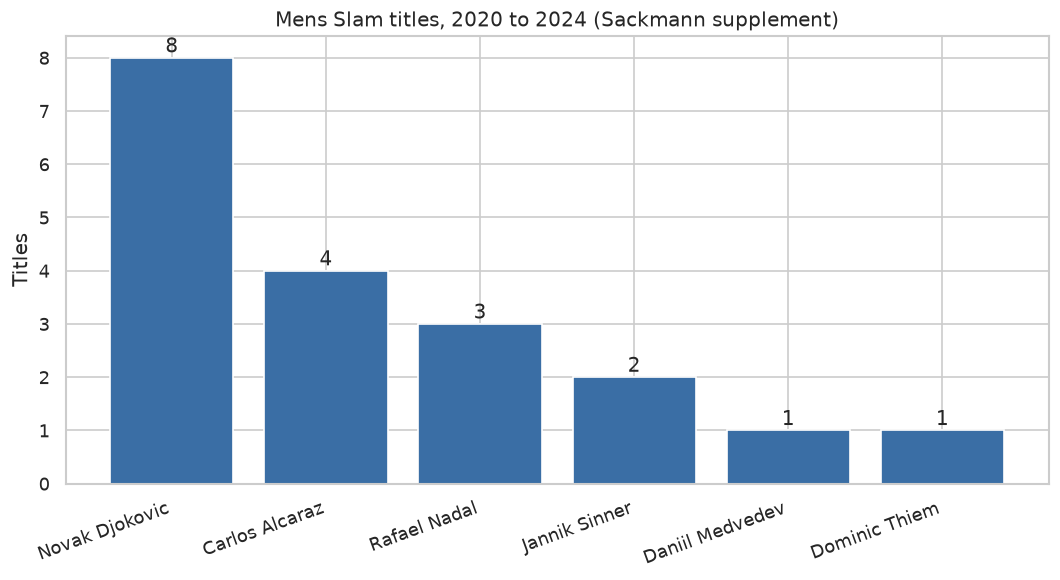

In [5]:
vals = recent.groupby('winner_name').size().sort_values(ascending=False)
plt.figure(figsize=(9, 5)); plt.bar(vals.index, vals.values, color='#3a6ea5')
plt.title('Mens Slam titles, 2020 to 2024 (Sackmann supplement)'); plt.ylabel('Titles'); plt.xticks(rotation=20, ha='right')
for i, v in enumerate(vals.values): plt.text(i, v + 0.1, str(v), ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/06_recent_slam_titles.png'); plt.show()

## Chart: women's Slam titles, 2000 to 2024, top winners, Sackmann supplement.

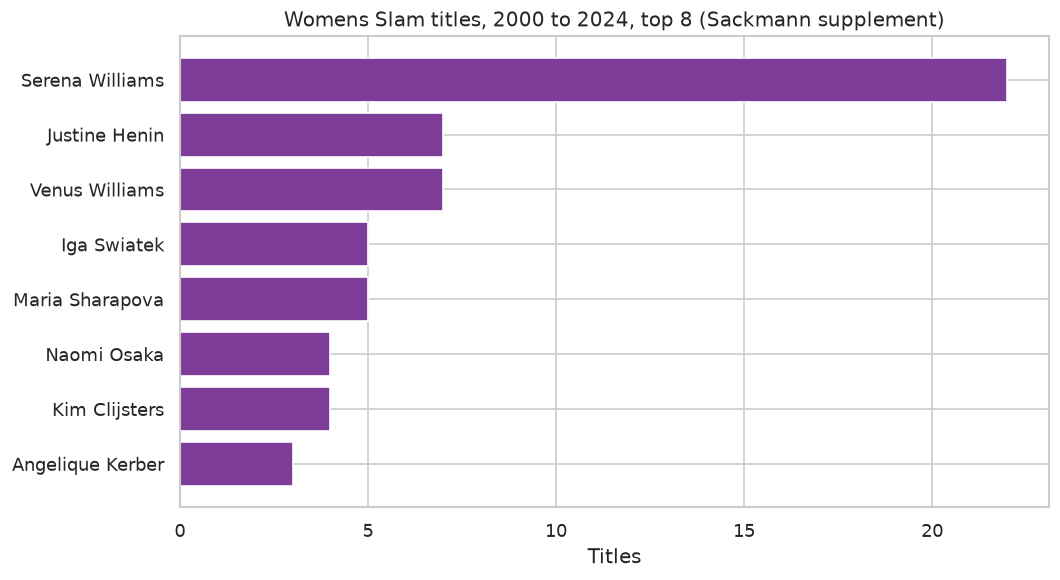

In [6]:
wvals = wta_fin.groupby('winner_name').size().sort_values(ascending=False).head(8)
plt.figure(figsize=(9, 5)); plt.barh(wvals.index[::-1], wvals.values[::-1], color='#7d3c98')
plt.title('Womens Slam titles, 2000 to 2024, top 8 (Sackmann supplement)'); plt.xlabel('Titles')
plt.tight_layout(); plt.savefig(f'{CH}/06_wta_titles.png'); plt.show()

## Chart: full tour matches by surface, Sackmann ATP 2000 to 2024. Hard courts dominate the tour calendar, grass is a short season, and carpet fades away. This is why Slam only surface numbers and tour surface numbers differ.

surface
Hard      40871
Clay      24244
Grass      7699
Carpet     2039
NaN          53
Name: count, dtype: int64


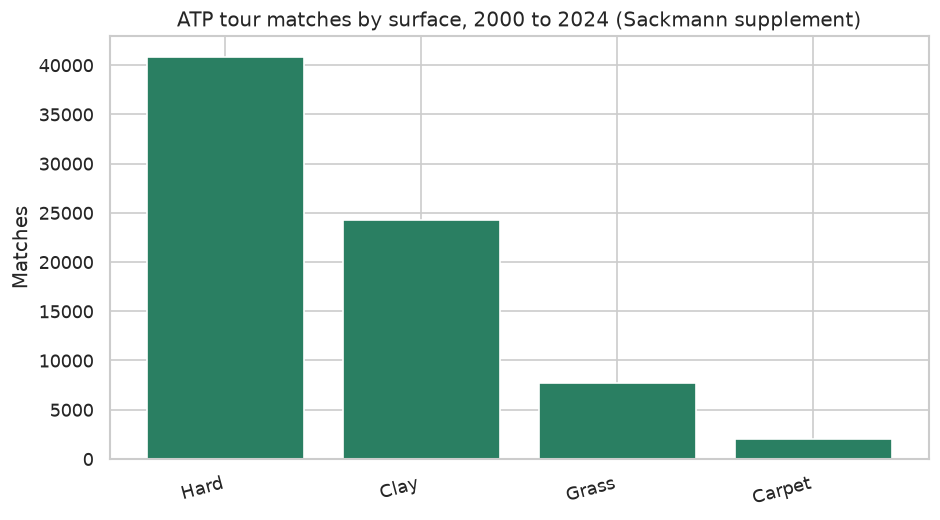

In [7]:
atp_full = pd.read_csv(f'{PROC}/sackmann_atp_2000_2024.csv', usecols=['surface'])
print(atp_full.surface.value_counts(dropna=False))
vals = atp_full.surface.value_counts()
plt.figure(figsize=(8, 4.5)); plt.bar(vals.index, vals.values, color='#2a7f62')
plt.title('ATP tour matches by surface, 2000 to 2024 (Sackmann supplement)'); plt.ylabel('Matches'); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.savefig(f'{CH}/06_tour_matches_by_surface.png'); plt.show()

## Limits that stay limits

The supplement has real serve stats for many tour matches, but coverage is uneven by year and event, so this project does not rebuild SDI on the full tour. The women's supplement is used only for Slam finals here, not for a full serve comparison, because the original repo has no women's serve data to compare it with. Both limits are kept in the BUILD_REPORT.